# Problem 9 · Advection of a pulse

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *Water flows round a closed loop of pipe, $L = 1$ m long, as a plug flow with speed $c = 1$ m/s. A pulse of dye is injected. The dye diffuses so slowly that it is simply carried by the flow, so after one lap, $t = L/c = 1$ s, it should be back where it started with exactly its initial shape. Predict the dye profile after one lap with the Finite Difference Method, for a smooth Gaussian pulse and a sharp square pulse, with three explicit schemes: FTCS, first-order upwind and Lax–Wendroff.*

Problem 5 carried a dye with a **steady** flow and found that central differences wiggle and upwind smears. Problem 2 marched an **unsteady** diffusion equation in time and met the stability limit $r \le 1/2$. Here both ideas meet in the simplest equation of fluid dynamics, pure transport: $\partial u/\partial t + c\,\partial u/\partial x = 0$. It has no diffusion at all, so every bit of smearing or wiggling we see is made by the numerical scheme.

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | unroll the loop into a periodic domain $0 \le x \le L$; define the two pulses |
| 2 · Grid | nodes in space *and* time, the Courant number $C = c\,\Delta t/\Delta x$ |
| 3 · Physics | the advection equation, a **hyperbolic** equation, and its exact solution |
| 4 · Numerical scheme | FTCS, upwind and Lax–Wendroff; the CFL condition; von Neumann analysis |
| 5 · Solution setup | explicit time marching with periodic neighbours |
| 6 · Compute | one lap at $C = 0.5$, then $C = 1.0$ and $C = 1.1$; the whiteboard numbers |
| 7 · Post-processing | numerical diffusion (the modified equation), dispersion, conservation, error study |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only imports used in the calculations are `math` and `time` (both part of Python itself). The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: exp, sin, cos, sqrt, atan2, log
import time     # built into Python: measure the run time
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

A closed loop of pipe of length $L$ (measured along its centre line) is full of water that circulates with a uniform speed $c$ (a **plug flow**: every particle moves at the same speed). At $t = 0$ a pulse of dye is in the loop. Over one lap the molecular diffusion of a dye in water is tiny ($D \approx 10^{-9}$ m²/s, so in 1 s it spreads by about $\sqrt{2Dt} \approx 0.05$ mm), so we neglect it completely: the dye is **only carried** by the flow.

We measure the position $x$ along the loop from a fixed point. Unrolling the loop gives a straight domain $0 \le x \le L$ whose two ends are **the same point**: whatever leaves at $x = L$ comes back in at $x = 0$. This is a **periodic** domain.

| Quantity | Symbol | Value |
|---|:-:|---|
| length of the loop | $L$ | 1.0 m |
| flow speed | $c$ | 1.0 m/s |
| time for one lap | $t_{lap} = L/c$ | 1.0 s |
| Gaussian pulse: centre, width | $x_0$, $\sigma$ | 0.5 m, 0.05 m |
| square pulse: from, to | | 0.4 m to 0.6 m, height 1 |

The dye concentration $u$ is scaled so that the pulses have height 1.

In [2]:
L = 1.0           # length of the loop                       [m]
c = 1.0           # flow speed (plug flow)                   [m/s]
t_lap = L / c     # time for one lap                         [s]

x0 = 0.5          # centre of both pulses                    [m]
sigma = 0.05      # width (standard deviation) of the Gaussian [m]
width = 0.2       # width of the square pulse                [m]

print(f"one lap takes t = L/c = {t_lap:g} s")

one lap takes t = L/c = 1 s


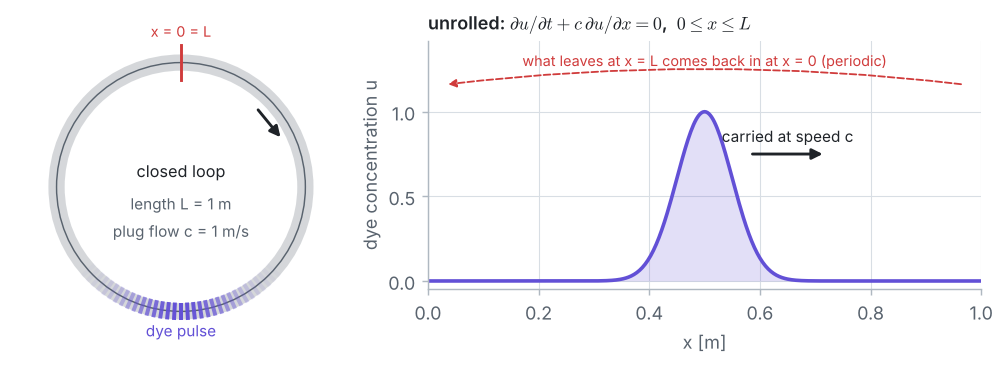

In [3]:
plots.schematic(L, c, lambda xx: math.exp(-(xx - x0)**2 / (2 * sigma**2)))

The two initial pulses test two different things. The **Gaussian** is smooth: a good scheme should get it right, and on finer grids the error should fall at the scheme's order of accuracy. The **square pulse** has two jumps, like the front and back of a slug of dye: it contains waves of every length, down to the shortest the grid can carry, and shows what a scheme does to them.

In [4]:
def gaussian(xx):
    """Smooth pulse, height 1, centred at x0."""
    return math.exp(-(xx - x0)**2 / (2 * sigma**2))


def square(xx):
    """Sharp pulse: 1 between x0 - width/2 and x0 + width/2, else 0."""
    return 1.0 if abs(xx - x0) <= width / 2 + 1e-9 else 0.0     # 1e-9: tolerance for round-off


pulses = {"Gaussian pulse": gaussian, "square pulse": square}

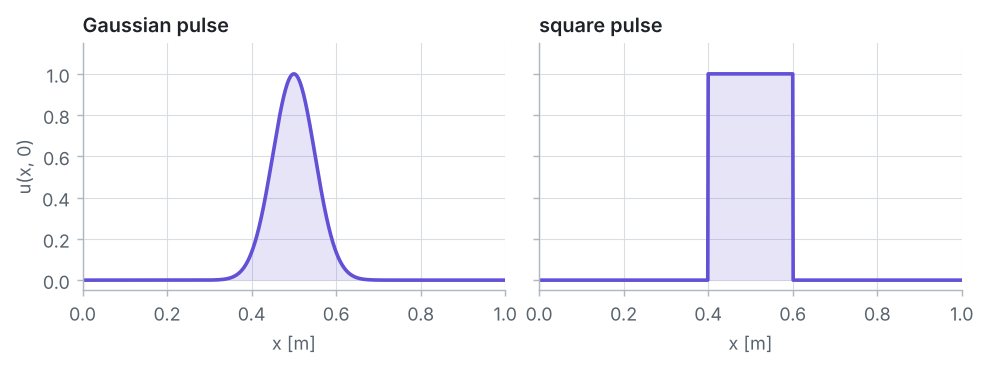

In [5]:
plots.initial(L, pulses)

---
## Pillar 2 · The grid in space and time

**Space.** We divide the loop into $N$ intervals of length $\Delta x = L/N$. Because the domain is periodic, node $N$ (at $x = L$) **is** node 0, so we store only the $N$ nodes $i = 0, 1, \dots, N-1$:

$$x_i = i\,\Delta x, \qquad i = 0, 1, \dots, N - 1.$$

Every node has two neighbours, also at the ends: the west neighbour of node 0 is node $N - 1$, and the east neighbour of node $N - 1$ is node 0. There are **no boundary nodes** and no boundary conditions to apply.

**Time.** As in Problem 2, we march in time steps $\Delta t$: $t^n = n\,\Delta t$, and $u_i^n$ is the value at node $i$ and time level $n$.

**The Courant number.** In one time step the flow moves the dye a distance $c\,\Delta t$. Measured in grid intervals, this is the **Courant number** (or CFL number, after Courant, Friedrichs and Lewy, 1928):

$$C = \frac{c\,\Delta t}{\Delta x} = \frac{\text{distance the flow moves in one step}}{\text{grid spacing}}.$$

It plays the role of $r = \alpha\,\Delta t/\Delta x^2$ in Problem 2. We choose the grid and the Courant number, and the time step follows: $\Delta t = C\,\Delta x/c$.

In [6]:
N = 100                 # number of intervals = number of stored nodes
dx = L / N              # grid spacing [m]
x = []                  # positions of the nodes 0 .. N-1 (node N is node 0 again)
for i in range(N):
    x.append(i * dx)

C = 0.5                 # Courant number
dt = C * dx / c         # time step [s]
n_lap = round(t_lap / dt)

print(f"N = {N} intervals, dx = {dx:g} m, nodes x_0 = {x[0]:g} ... x_{N - 1} = {x[-1]:g} m")
print(f"C = {C:g}  ->  dt = C dx / c = {dt:g} s,  {n_lap} time steps for one lap")

N = 100 intervals, dx = 0.01 m, nodes x_0 = 0 ... x_99 = 0.99 m
C = 0.5  ->  dt = C dx / c = 0.005 s,  200 time steps for one lap


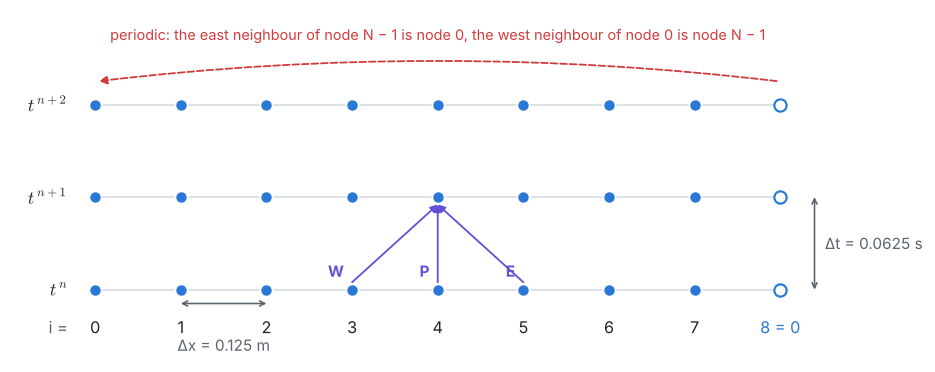

In [7]:
plots.grid([i * L / 8 for i in range(8)], 0.0625)

---
## Pillar 3 · Physics: the advection equation

Take a short piece of the pipe between $x$ and $x + dx$. Dye enters at $x$ with the flux $c\,u(x)$ and leaves at $x + dx$ with the flux $c\,u(x + dx)$; nothing else changes the amount of dye inside. The balance gives the **linear advection equation**:

$$\frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = 0, \qquad 0 \le x \le L, \qquad u(0, t) = u(L, t), \qquad u(x, 0) = u_0(x).$$

It is the convection–diffusion equation of Problem 5 with the time derivative put back and **no diffusion**. It is the simplest example of a **hyperbolic** equation (see the table of model equations on the course home page): information travels along particular lines at a finite speed.

**Characteristics.** Along any line $x - c\,t = \text{const}$ in the $x$–$t$ plane, $u$ does not change:

$$\frac{d}{dt}\,u(x_0 + c\,t,\ t) = \frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = 0.$$

These lines are called **characteristics**. Each value of $u$ is simply carried along its characteristic, so the **exact solution** is the initial profile shifted by $c\,t$:

$$u(x, t) = u_0(x - c\,t),$$

with $x - c\,t$ wrapped back into $[0, L)$ because the loop is periodic. After one lap, $t = L/c$, the profile is **exactly** the initial one. This is what makes the problem such a good test: we always know the right answer, and every change of shape is a numerical error.

Compare with Problems 1–4 (elliptic: every point feels every other point at once) and Problem 2 (parabolic: a change is felt everywhere immediately, but fades). Here a change travels with speed $c$, **in one direction only**, and never fades.

In [8]:
def u_exact(xx, t, pulse):
    """Exact solution: the initial pulse shifted by c t around the periodic loop."""
    return pulse((xx - c * t) % L)       # % L wraps x - c t back into [0, L)


for t in (0.0, 0.25, 1.0):
    print(f"t = {t:4.2f} s:  exact Gaussian at x = 0.50 and 0.75 m:  "
          f"{u_exact(0.50, t, gaussian):.4f}  {u_exact(0.75, t, gaussian):.4f}")

t = 0.00 s:  exact Gaussian at x = 0.50 and 0.75 m:  1.0000  0.0000
t = 0.25 s:  exact Gaussian at x = 0.50 and 0.75 m:  0.0000  1.0000
t = 1.00 s:  exact Gaussian at x = 0.50 and 0.75 m:  1.0000  0.0000


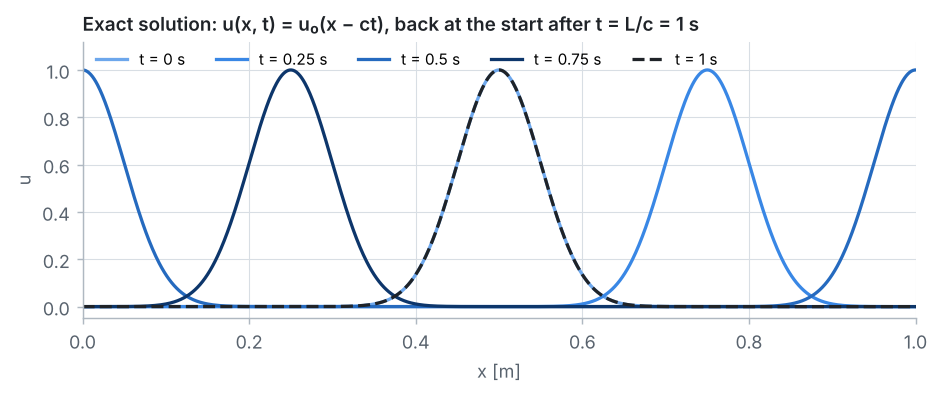

In [9]:
plots.exact_snapshots(L, c, lambda xx, t: u_exact(xx, t, gaussian), [0, 0.25, 0.5, 0.75, 1.0])

---
## Pillar 4 · Numerical scheme: three explicit schemes

All three schemes compute the new value $u_i^{n+1}$ at a node from the old values at the same node $P = i$ and its neighbours $W = i - 1$ and $E = i + 1$. The time derivative is always the **forward difference** $(u_i^{n+1} - u_i^n)/\Delta t$ of Problem 2. They differ in how they treat $\partial u/\partial x$. Multiplying by $\Delta t$ brings in the Courant number $C = c\,\Delta t/\Delta x$.

**Scheme A: FTCS** (forward in time, central in space). The obvious choice, the scheme that worked for diffusion in Problem 2:

$$u_i^{n+1} = u_i^n - \frac{C}{2}\left(u_{i+1}^n - u_{i-1}^n\right).$$

**Scheme B: first-order upwind.** As in Problem 5, use only the node the flow comes **from**. For $c > 0$ that is the west node:

$$u_i^{n+1} = u_i^n - C\left(u_i^n - u_{i-1}^n\right) = (1 - C)\,u_i^n + C\,u_{i-1}^n.$$

**Scheme C: Lax–Wendroff** (1960). Expand the new value in a Taylor series in time, $u^{n+1} = u^n + \Delta t\,u_t + \tfrac{1}{2}\Delta t^2\,u_{tt} + \dots$, and use the equation itself to turn time derivatives into space derivatives: $u_t = -c\,u_x$ and $u_{tt} = c^2\,u_{xx}$. With central differences for $u_x$ and $u_{xx}$:

$$u_i^{n+1} = u_i^n - \frac{C}{2}\left(u_{i+1}^n - u_{i-1}^n\right) + \frac{C^2}{2}\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right).$$

It is FTCS plus a diffusion-like term of exactly the right size to make the scheme **2nd order** in both $\Delta x$ and $\Delta t$. FTCS and upwind are 1st order in time.

In code, Python's negative indices do the periodic wrap for us: for $i = 0$, `u[i - 1]` is `u[-1]`, the last node. For the east neighbour we use `u[(i + 1) % N]`, which is `u[0]` for $i = N - 1$.

In [10]:
def step_ftcs(u, C):
    """One time step of FTCS: forward in time, central in space."""
    N = len(u)
    new = [0.0] * N
    for i in range(N):
        W, P, E = u[i - 1], u[i], u[(i + 1) % N]     # periodic neighbours
        new[i] = P - C / 2 * (E - W)
    return new


def step_upwind(u, C):
    """One time step of first-order upwind (flow from left to right, c > 0)."""
    N = len(u)
    new = [0.0] * N
    for i in range(N):
        W, P = u[i - 1], u[i]                         # u[-1] is the last node: periodic
        new[i] = P - C * (P - W)
    return new


def step_lax_wendroff(u, C):
    """One time step of Lax-Wendroff: FTCS plus the term C^2/2 (E - 2P + W)."""
    N = len(u)
    new = [0.0] * N
    for i in range(N):
        W, P, E = u[i - 1], u[i], u[(i + 1) % N]
        new[i] = P - C / 2 * (E - W) + C**2 / 2 * (E - 2 * P + W)
    return new


schemes = {"FTCS": step_ftcs, "upwind": step_upwind, "Lax-Wendroff": step_lax_wendroff}

### The CFL condition

The exact value at node $P$ at the new time is carried along the characteristic that passes through $P$ at $t^{n+1}$. Followed back one time step, it starts at $x_P - c\,\Delta t$, a distance $C\,\Delta x$ upstream. All three schemes build $u_P^{n+1}$ from the nodes $W$, $P$ (and $E$) only. If $C > 1$, the characteristic starts **outside** the stencil, beyond $W$: the scheme uses none of the information that actually decides the answer. Courant, Friedrichs and Lewy showed that a scheme can then not converge:

$$\textbf{CFL condition:}\qquad C = \frac{c\,\Delta t}{\Delta x} \le 1.$$

It is a **necessary** condition, not a sufficient one: FTCS satisfies it and still fails, as the next section shows.

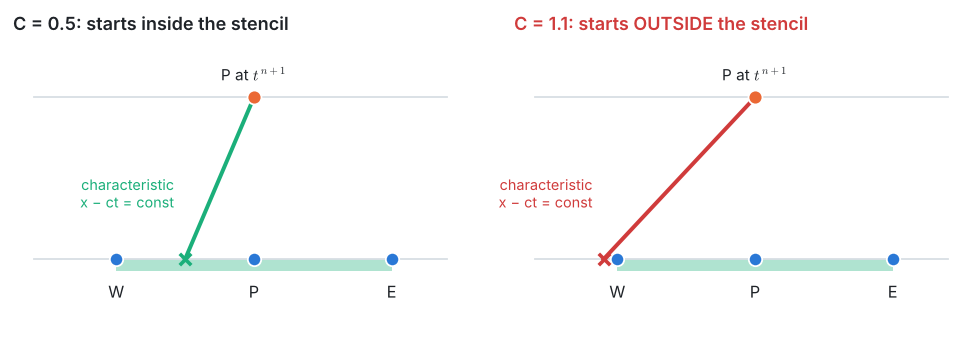

In [11]:
plots.domain_of_dependence([0.5, 1.1])

### Von Neumann stability analysis

Any grid function can be written as a sum of waves $e^{\,\mathrm{i}\,k x}$ (a Fourier series). In a linear scheme every wave evolves on its own, so we follow one wave, $u_i^n = G^n\,e^{\,\mathrm{i}\,\theta i}$, where $\theta = k\,\Delta x$ is the change of phase from one node to the next ($\theta = \pi$ is the shortest wave on the grid, $2\Delta x$ long, with node values $+1, -1, +1, \dots$). Putting it into a scheme and dividing by $u_i^n$ gives the **amplification factor** $G$, the factor by which the wave is multiplied in one time step. With $u_{i\pm1}^n = e^{\pm\mathrm{i}\theta}\,u_i^n$:

$$G_{FTCS} = 1 - \mathrm{i}\,C\sin\theta, \qquad |G_{FTCS}|^2 = 1 + C^2\sin^2\theta,$$

$$G_{upwind} = 1 - C\left(1 - e^{-\mathrm{i}\theta}\right), \qquad |G_{upwind}|^2 = 1 - 2C(1 - C)(1 - \cos\theta),$$

$$G_{LW} = 1 - \mathrm{i}\,C\sin\theta - C^2(1 - \cos\theta), \qquad |G_{LW}|^2 = 1 - C^2(1 - C^2)(1 - \cos\theta)^2.$$

The exact solution only shifts every wave, so its $|G| = 1$. A scheme is **stable** if no wave grows: $|G| \le 1$ for every $\theta$.

* **FTCS:** $|G|^2 = 1 + C^2\sin^2\theta > 1$ for every $C > 0$. Every wave grows, a little at every step, whatever the time step: **unconditionally unstable**.
* **Upwind:** $|G| \le 1$ exactly when $0 \le C \le 1$. For $C < 1$, $|G| < 1$: the waves are **damped**, the short ones most.
* **Lax–Wendroff:** $|G| \le 1$ exactly when $C \le 1$; the damping is much weaker (it grows like $\theta^4$ instead of $\theta^2$).

The phase of $G$ tells how far a wave moves in one step; dividing by the exact shift $C\,\theta$ gives the **numerical speed** of each wave as a fraction of $c$. Python handles complex numbers itself (`1j` is $\mathrm{i}$):

In [12]:
def amplification(scheme, C, theta):
    """Amplification factor G of one wave exp(i theta i) per time step (a complex number)."""
    if scheme == "FTCS":
        return 1 - 1j * C * math.sin(theta)
    if scheme == "upwind":
        return 1 - C * (1 - (math.cos(theta) - 1j * math.sin(theta)))      # e^{-i theta}
    return 1 - 1j * C * math.sin(theta) - C**2 * (1 - math.cos(theta))     # Lax-Wendroff


def speed_ratio(G, C, theta):
    """Numerical speed of the wave divided by c: -phase(G) / (C theta)."""
    return -math.atan2(G.imag, G.real) / (C * theta)


for C_test in (0.5, 1.0, 1.1):
    print(f"C = {C_test}:")
    for scheme in schemes:
        line = "   ".join(f"{abs(amplification(scheme, C_test, th)):.4f}"
                          for th in (math.pi / 4, math.pi / 2, math.pi))
        print(f"   {scheme:13s} |G| at theta = pi/4, pi/2, pi:   {line}")

C = 0.5:
   FTCS          |G| at theta = pi/4, pi/2, pi:   1.0607   1.1180   1.0000
   upwind        |G| at theta = pi/4, pi/2, pi:   0.9239   0.7071   0.0000
   Lax-Wendroff  |G| at theta = pi/4, pi/2, pi:   0.9919   0.9014   0.5000
C = 1.0:
   FTCS          |G| at theta = pi/4, pi/2, pi:   1.2247   1.4142   1.0000
   upwind        |G| at theta = pi/4, pi/2, pi:   1.0000   1.0000   1.0000
   Lax-Wendroff  |G| at theta = pi/4, pi/2, pi:   1.0000   1.0000   1.0000
C = 1.1:
   FTCS          |G| at theta = pi/4, pi/2, pi:   1.2669   1.4866   1.0000
   upwind        |G| at theta = pi/4, pi/2, pi:   1.0317   1.1045   1.2000
   Lax-Wendroff  |G| at theta = pi/4, pi/2, pi:   1.0108   1.1199   1.4200


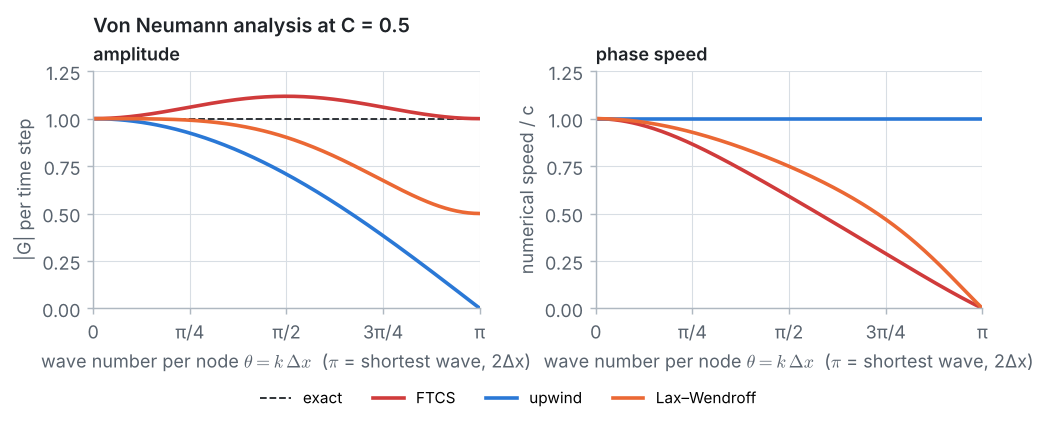

In [13]:
thetas = [math.pi * j / 200 for j in range(1, 201)]
curves = {}
for scheme in schemes:
    Gs = [amplification(scheme, C, th) for th in thetas]
    curves[scheme] = (thetas, [abs(G) for G in Gs], [speed_ratio(G, C, th) for G, th in zip(Gs, thetas)])
plots.amplification(curves, C)

At $C = 0.5$: FTCS amplifies every wave (most of all $\theta = \pi/2$, a wave $4\Delta x$ long, by $\sqrt{1.25} = 1.118$ per step). Upwind damps all waves, and kills the $2\Delta x$ wave in a single step ($|G| = 0$). At exactly $C = 0.5$ every upwind wave travels at the right speed (its phase-speed line lies on the exact one): its whole error is damping. Lax–Wendroff keeps the long waves almost untouched, but its short waves travel **too slowly**: they fall behind the pulse. At $C = 1$ upwind and Lax–Wendroff have $|G| = 1$ for every wave. At $C = 1.1$ both amplify the short waves.

---
## Pillar 5 · Solution setup: explicit time marching

All three schemes are **explicit**: each new value comes straight from old values, with no system of equations to solve (unlike Problems 1, 3–7). We start from the initial pulse at the nodes and apply one step after another. For one lap we need $n = t_{lap}/\Delta t = N/C$ steps.

In [14]:
def solve(pulse, scheme, N, C, t_end=t_lap, record=None):
    """March from u0 at the N nodes to t_end; returns the node positions, u and the final time.

    If record is a list, the largest |u| of every step is appended to it.
    """
    dx = L / N
    dt = C * dx / c
    n_steps = round(t_end / dt)
    step = schemes[scheme]
    x_nodes = [i * dx for i in range(N)]
    u = [pulse(xi) for xi in x_nodes]          # initial condition
    for n in range(n_steps):
        u = step(u, C)
        if record is not None:
            record.append(max(abs(v) for v in u))
    return x_nodes, u, n_steps * dt


def largest_error(x_nodes, u, t, pulse):
    """Largest difference from the exact solution at the nodes."""
    return max(abs(u[i] - u_exact(x_nodes[i], t, pulse)) for i in range(len(u)))

---
## Pillar 6 · Compute

### FTCS: it always blows up

We run FTCS at $C = 0.5$ on our grid of 100 intervals and watch the largest value of $|u|$. The exact answer never exceeds 1.

In [15]:
ftcs_growth = {}
for name, pulse in pulses.items():
    record = []
    xs, u, t = solve(pulse, "FTCS", N, C, record=record)
    ftcs_growth[name] = ([(n + 1) * dt for n in range(len(record))], record)
    print(f"{name:15s} FTCS, C = {C}:  largest |u| after one lap = {record[-1]:.3g}"
          f"   (after 0.25 s: {record[n_lap // 4 - 1]:.3g})")

for C_small in (0.25, 0.1):
    xs, u, t = solve(gaussian, "FTCS", N, C_small)
    print(f"Gaussian pulse  FTCS, C = {C_small}: largest |u| after one lap = {max(abs(v) for v in u):.3g}")

Gaussian pulse  FTCS, C = 0.5:  largest |u| after one lap = 69.7   (after 0.25 s: 1.33)
square pulse    FTCS, C = 0.5:  largest |u| after one lap = 4.02e+08   (after 0.25 s: 32.5)
Gaussian pulse  FTCS, C = 0.25: largest |u| after one lap = 1.72
Gaussian pulse  FTCS, C = 0.1: largest |u| after one lap = 1.16


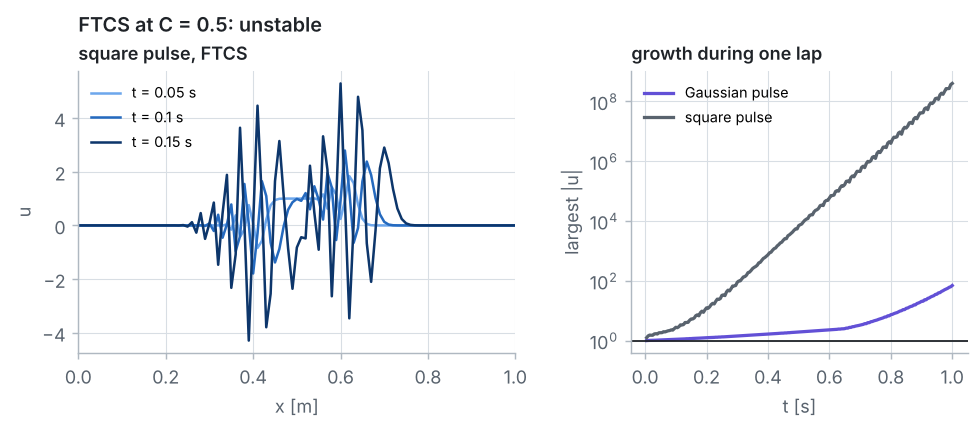

In [16]:
snapshots = {}
for t_snap in (0.05, 0.1, 0.15):
    xs, u, t = solve(square, "FTCS", N, C, t_end=t_snap)
    snapshots[t_snap] = u
plots.ftcs_blowup(x, snapshots, ftcs_growth, C)

The square pulse grows wiggles at once; after one lap its values are in the hundreds of millions. Even the smooth Gaussian, which contains almost no short waves, reaches values near 70. A smaller time step only delays the disaster, because $|G| > 1$ for **every** $C > 0$. The central difference that worked so well for diffusion (Problem 2) and for steady convection with enough diffusion (Problem 5) cannot be combined with a forward step in time for pure advection. From now on we drop FTCS.

### Upwind and Lax–Wendroff: one lap at $C = 0.5$

In [17]:
def report(scheme, N, C, pulse_names=pulses):
    """Run one lap and print peak, minimum and largest error for each pulse."""
    out = {}
    for name in pulse_names:
        xs, u, t = solve(pulses[name], scheme, N, C)
        err = largest_error(xs, u, t, pulses[name])
        out[name] = u
        print(f"   {scheme:12s}  {name:14s}  peak {max(u):9.4g}   min {min(u):9.4g}"
              f"   largest error {err:8.3g}   t = {t:.4g} s")
    return out


print(f"N = {N}, C = {C}, one lap ({n_lap} steps); exact: peak 1, min 0")
lap = {name: {} for name in pulses}
for scheme in ("upwind", "Lax-Wendroff"):
    result = report(scheme, N, C)
    for name in pulses:
        lap[name][scheme] = result[name]

N = 100, C = 0.5, one lap (200 steps); exact: peak 1, min 0
   upwind        Gaussian pulse  peak     0.577   min 5.612e-08   largest error    0.423   t = 1 s
   upwind        square pulse    peak    0.8626   min 1.507e-08   largest error    0.474   t = 1 s
   Lax-Wendroff  Gaussian pulse  peak    0.9639   min  -0.03069   largest error    0.129   t = 1 s
   Lax-Wendroff  square pulse    peak     1.223   min   -0.2207   largest error    0.596   t = 1 s


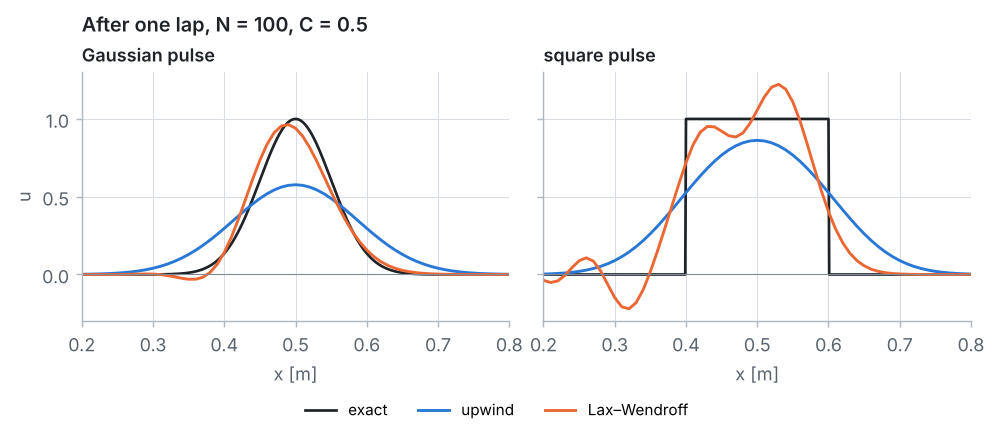

In [18]:
plots.one_lap(x, lap, {name: (lambda xx, p=p: u_exact(xx, t_lap, p)) for name, p in pulses.items()},
              f"After one lap, N = {N}, C = {C:g}")

The two stable schemes go wrong in two **opposite** ways:

* **Upwind smears.** The Gaussian comes back at the right place but at only 58 % of its height and much wider; the square pulse is rounded into a bump with peak 0.86. No value is negative or above 1: the scheme is **bounded** (the new value is a weighted average $(1 - C)\,u_P + C\,u_W$ with positive weights, exactly the argument of Problem 5). This is **numerical diffusion**.
* **Lax–Wendroff wiggles.** The Gaussian keeps 96 % of its height, but a small dip below zero trails behind it. Behind both edges of the square pulse a train of wiggles appears, overshooting to 1.22 and undershooting to −0.22. The short waves of the jumps travel too slowly (the phase-speed plot above) and fall behind: **numerical dispersion**.

### Changing the Courant number: $C = 1.0$ and $C = 1.1$

With $N = 100$ fixed, $C = 1$ means $\Delta t = 0.01$ s and 100 steps per lap. For $C = 1.1$, one lap is not a whole number of steps: we take the nearest, 91 steps, which ends at $t = 1.001$ s, and compare with the exact solution at that time.

In [19]:
for C_run in (0.5, 1.0, 1.1):
    print(f"C = {C_run}:")
    for scheme in ("upwind", "Lax-Wendroff"):
        report(scheme, N, C_run)

C = 0.5:
   upwind        Gaussian pulse  peak     0.577   min 5.612e-08   largest error    0.423   t = 1 s
   upwind        square pulse    peak    0.8626   min 1.507e-08   largest error    0.474   t = 1 s
   Lax-Wendroff  Gaussian pulse  peak    0.9639   min  -0.03069   largest error    0.129   t = 1 s
   Lax-Wendroff  square pulse    peak     1.223   min   -0.2207   largest error    0.596   t = 1 s
C = 1.0:
   upwind        Gaussian pulse  peak         1   min 1.929e-22   largest error 6.66e-16   t = 1 s
   upwind        square pulse    peak         1   min         0   largest error        0   t = 1 s
   Lax-Wendroff  Gaussian pulse  peak         1   min 1.929e-22   largest error 6.66e-16   t = 1 s
   Lax-Wendroff  square pulse    peak         1   min         0   largest error        0   t = 1 s
C = 1.1:
   upwind        Gaussian pulse  peak     1.274   min -0.001333   largest error    0.279   t = 1.001 s
   upwind        square pulse    peak 1.227e+06   min -1.227e+06   largest err

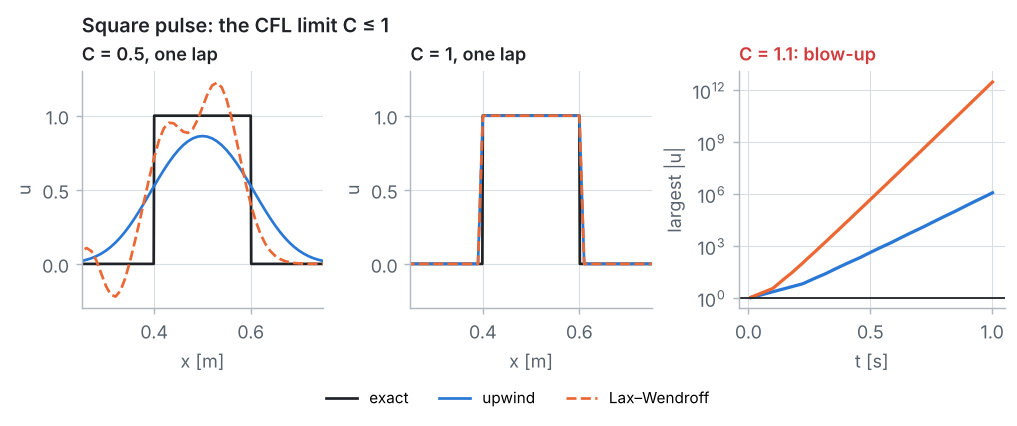

In [20]:
laps = {}
for C_run in (0.5, 1.0):
    laps[C_run] = {scheme: solve(square, scheme, N, C_run)[1] for scheme in ("upwind", "Lax-Wendroff")}
blowup = {}
for scheme in ("upwind", "Lax-Wendroff"):
    record = []
    xs, u, t = solve(square, scheme, N, 1.1, record=record)
    blowup[scheme] = ([(n + 1) * 1.1 * dx / c for n in range(len(record))], record)
plots.cfl_study(x, laps, blowup, lambda xx: u_exact(xx, t_lap, square))

* **$C = 1$: both schemes are exact.** With $C = 1$ upwind becomes $u_i^{n+1} = u_{i-1}^n$, and Lax–Wendroff too (put $C = 1$ in its formula: the $u_i$ and $u_{i+1}$ terms cancel). Each step copies every value exactly one node downstream, which is exactly what the flow does in $\Delta t = \Delta x/c$. The error is zero (to round-off), for both pulses. The characteristic through $P$ starts exactly at $W$.
* **$C = 1.1$: both schemes blow up.** The CFL condition is violated, the shortest waves grow by $|G| = 1.2$ (upwind) and $1.42$ (Lax–Wendroff) per step, and the square pulse explodes within one lap. The smooth Gaussian has so little energy in its short waves that after one lap its errors are still modest (0.28 for upwind), but they grow without limit if we keep going.

So the Courant number is the single most important number of an explicit advection calculation: below 1 the scheme is stable but (except at exactly 1) inaccurate in its own way; above 1 it fails. In a real flow $c$ changes from place to place, so $C = 1$ cannot hold everywhere, and real codes run with $C$ somewhat below 1.

### Checking the whiteboard numbers

The whiteboard guide does two time steps by hand on the coarsest grid: $N = 8$ ($\Delta x = 0.125$ m), $C = 0.5$ ($\Delta t = 0.0625$ s). On this grid the square pulse ($0.4 \le x \le 0.6$) covers only node 4 ($x = 0.5$): a single spike. With $C = 0.5$ the three update formulas have simple weights:

$$\text{FTCS: } u_i^{n+1} = 0.25\,u_W + u_P - 0.25\,u_E, \qquad
\text{upwind: } u_i^{n+1} = 0.5\,u_W + 0.5\,u_P, \qquad
\text{LW: } u_i^{n+1} = 0.375\,u_W + 0.75\,u_P - 0.125\,u_E.$$

In two steps the flow moves the dye $2 \times 0.5 = 1$ interval: the exact answer is the spike at node 5. The *sum* $\sum u_i$ (the amount of dye) and the *sum of squares* $\sum u_i^2$ (which grows when waves grow, and falls when they are damped) tell the story:

In [21]:
N_hand, C_hand = 8, 0.5
x_hand = [i * L / N_hand for i in range(N_hand)]
u_start = [square(xi) for xi in x_hand]
hand_levels = {}
for scheme in schemes:
    levels = [u_start]
    for n in range(2):
        levels.append(schemes[scheme](levels[-1], C_hand))
    hand_levels[scheme] = levels
    print(f"{scheme}:")
    for n, u in enumerate(levels):
        values = "".join(f"{v:9.6g}" for v in u)
        print(f"   n = {n}: {values}   sum {sum(u):.6g}, sum of squares {sum(v * v for v in u):.6g}")
print("exact after 2 steps:", [square(xi - 2 * C_hand * L / N_hand) for xi in x_hand])

FTCS:
   n = 0:         0        0        0        0        1        0        0        0   sum 1, sum of squares 1
   n = 1:         0        0        0    -0.25        1     0.25        0        0   sum 1, sum of squares 1.125
   n = 2:         0        0   0.0625     -0.5    0.875      0.5   0.0625        0   sum 1, sum of squares 1.27344
upwind:
   n = 0:         0        0        0        0        1        0        0        0   sum 1, sum of squares 1
   n = 1:         0        0        0        0      0.5      0.5        0        0   sum 1, sum of squares 0.5
   n = 2:         0        0        0        0     0.25      0.5     0.25        0   sum 1, sum of squares 0.375
Lax-Wendroff:
   n = 0:         0        0        0        0        1        0        0        0   sum 1, sum of squares 1
   n = 1:         0        0        0   -0.125     0.75    0.375        0        0   sum 1, sum of squares 0.71875
   n = 2:         0        0 0.015625  -0.1875  0.46875   0.5625 0.140625     

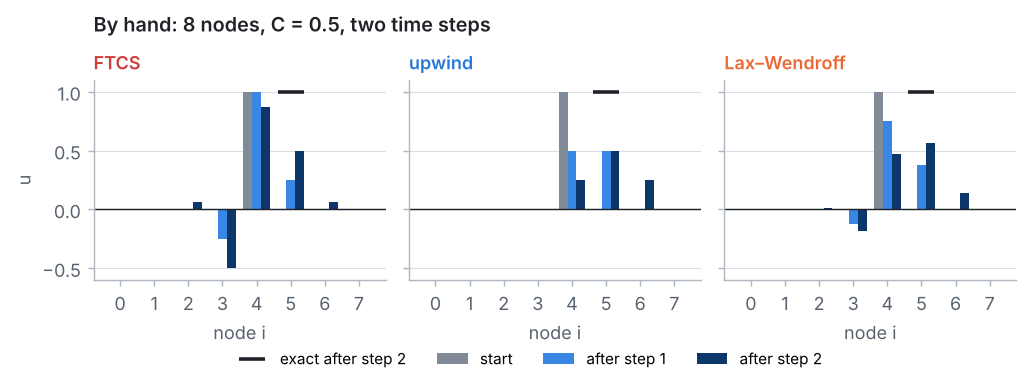

In [22]:
plots.hand(hand_levels, [square(xi - 2 * C_hand * L / N_hand) for xi in x_hand])

---
## Pillar 7 · Post-processing: what the schemes do to the pulse

### Upwind = advection + numerical diffusion (the modified equation)

Why does upwind smear? Expand both sides of the upwind formula in Taylor series about $(x_i, t^n)$:

$$u_i^{n+1} = u + \Delta t\,u_t + \tfrac{1}{2}\Delta t^2\,u_{tt} + \dots, \qquad u_{i-1}^n = u - \Delta x\,u_x + \tfrac{1}{2}\Delta x^2\,u_{xx} - \dots$$

Putting them into $(u_i^{n+1} - u_i^n)/\Delta t + c\,(u_i^n - u_{i-1}^n)/\Delta x = 0$:

$$u_t + c\,u_x = -\tfrac{1}{2}\Delta t\,u_{tt} + \tfrac{1}{2}c\,\Delta x\,u_{xx} + \dots$$

To leading order $u_{tt} = c^2\,u_{xx}$ (differentiate the advection equation twice), so the upwind scheme really solves

$$\boxed{\;u_t + c\,u_x = D_{num}\,u_{xx}, \qquad D_{num} = \frac{c\,\Delta x}{2}\,(1 - C)\;}$$

This is the **modified equation**: the equation the scheme actually solves, up to higher-order terms. The upwind scheme adds a **numerical diffusion** coefficient $D_{num}$. It is the false diffusion of Problem 5, $u\,\Delta x/2$ (there written as $\rho u\,\Delta x/2$, with $\Gamma/\rho$ as the diffusion coefficient), times $(1 - C)$: in an unsteady calculation part of it is cancelled by the error of the forward time step, all of it at $C = 1$, which is why $C = 1$ was exact.

The same expansion for FTCS gives $u_t + c\,u_x = -\tfrac{1}{2}c^2\Delta t\,u_{xx}$: a **negative** diffusion coefficient, which makes every bump sharper and taller until it blows up. Another way to see why FTCS is unstable.

**A prediction.** A Gaussian of width $\sigma$ that diffuses with coefficient $D$ for a time $t$ stays a Gaussian with $\sigma_t^2 = \sigma^2 + 2Dt$, and since the amount of dye is conserved, its peak falls to $\sigma/\sigma_t$. So the modified equation predicts the peak of the upwind solution after one lap without running the scheme:

In [23]:
def upwind_peak_predicted(N, C, t=t_lap):
    """Peak of the Gaussian after time t predicted by the modified equation of upwind."""
    D_num = c * (L / N) / 2 * (1 - C)
    return sigma / math.sqrt(sigma**2 + 2 * D_num * t), D_num


for C_run in (0.25, 0.5, 0.75, 1.0):
    predicted, D_num = upwind_peak_predicted(N, C_run)
    xs, u, t = solve(gaussian, "upwind", N, C_run)
    print(f"C = {C_run:4.2f}:  D_num = {D_num:.6f} m^2/s   predicted peak = {predicted:.4f}"
          f"   upwind peak = {max(u):.4f}")

C = 0.25:  D_num = 0.003750 m^2/s   predicted peak = 0.5000   upwind peak = 0.4998
C = 0.50:  D_num = 0.002500 m^2/s   predicted peak = 0.5774   upwind peak = 0.5770
C = 0.75:  D_num = 0.001250 m^2/s   predicted peak = 0.7071   upwind peak = 0.7073
C = 1.00:  D_num = 0.000000 m^2/s   predicted peak = 1.0000   upwind peak = 1.0000


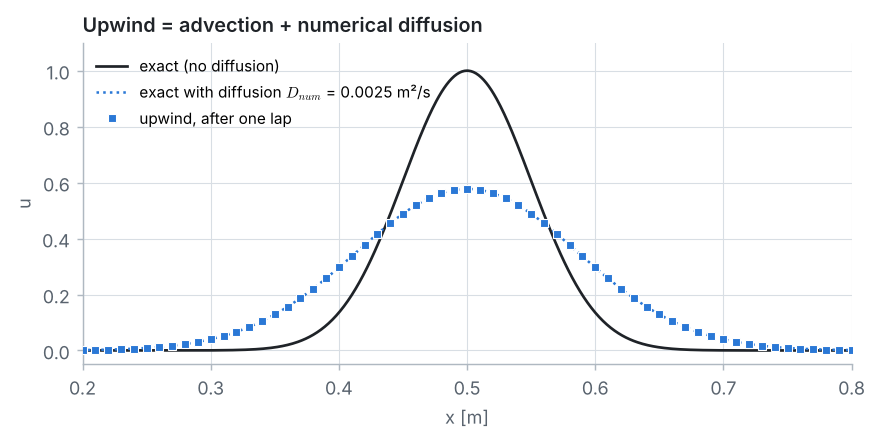

In [24]:
predicted, D_num = upwind_peak_predicted(N, C)
s_t = math.sqrt(sigma**2 + 2 * D_num * t_lap)
plots.modified_equation(x, lap["Gaussian pulse"]["upwind"], lambda xx: u_exact(xx, t_lap, gaussian),
                        lambda xx: sigma / s_t * math.exp(-(xx - x0)**2 / (2 * s_t**2)), D_num)

The prediction and the computed peak agree to within 0.0005 at every Courant number. At $C = 0.5$ the numerical diffusion is $D_{num} = 0.0025$ m²/s, **2.5 million times** the real diffusion of a dye in water ($10^{-9}$ m²/s): the upwind result looks like a pulse of dye in a very diffusive fluid. The smaller the time step, the *worse* upwind gets on a fixed grid ($C = 0.25$ keeps only 50 % of the peak): reducing $\Delta t$ does not reduce the error that comes from $\Delta x$.

**Lax–Wendroff.** The same expansion gives

$$u_t + c\,u_x = -\frac{c\,\Delta x^2}{6}\,(1 - C^2)\,u_{xxx} + \dots$$

The leading error has a **third** derivative: it does not damp waves, it changes their speed (**dispersion**), and short waves are the most affected. That is the train of wiggles behind the square pulse. Only a weaker, fourth-order damping remains, which is why the Gaussian kept 96 % of its peak.

### Conservation of the dye

All three schemes can be written as "new = old − (flux out − flux in)", so the total amount of dye, $\sum u_i\,\Delta x$, never changes on a periodic grid, even when the profile is badly wrong:

In [25]:
for name, pulse in pulses.items():
    total_start = sum(pulse(xi) for xi in x) * dx
    line = "   ".join(f"{scheme}: {sum(lap[name][scheme]) * dx:.6f}" for scheme in lap[name])
    print(f"{name:15s} amount of dye at t = 0: {total_start:.6f}   after one lap:  {line}")

Gaussian pulse  amount of dye at t = 0: 0.125331   after one lap:  upwind: 0.125331   Lax-Wendroff: 0.125331
square pulse    amount of dye at t = 0: 0.210000   after one lap:  upwind: 0.210000   Lax-Wendroff: 0.210000


Upwind spreads the dye, Lax–Wendroff moves some of it into wiggles, but neither loses or creates any. A scheme can be conservative and still inaccurate.

### Verification: the error study

For the smooth Gaussian we can measure the order of accuracy. We keep $C = 0.5$ fixed (so $\Delta t$ shrinks with $\Delta x$), run one lap on grids from $N = 25$ to $1600$ intervals, and record the largest error at the nodes and the peak (for upwind, the peak predicted by the modified equation is shown in brackets). As in Problem 5, the observed order between two grids is $p = \log(e_{coarse}/e_{fine})/\log 2$.

In [26]:
grids = [25, 50, 100, 200, 400, 800, 1600]
dxs, errors, peaks = [], {"upwind": [], "Lax-Wendroff": []}, {"upwind": [], "Lax-Wendroff": []}
start = time.time()
print("                |               upwind               |      Lax-Wendroff")
print("     N   steps  |    error  order    peak (theory)  |    error  order     peak")
for n_int in grids:
    line = f"{n_int:6d}  {round(n_int / C):6d}  |"
    for scheme in ("upwind", "Lax-Wendroff"):
        xs, u, t = solve(gaussian, scheme, n_int, C)
        error = largest_error(xs, u, t, gaussian)
        e = errors[scheme]
        order = f"{math.log(e[-1] / error) / math.log(2):5.2f}" if e else "     "
        e.append(error)
        peaks[scheme].append(max(u))
        if scheme == "upwind":
            line += f" {error:8.2e}  {order}  {max(u):.4f} ({upwind_peak_predicted(n_int, C)[0]:.4f})  |"
        else:
            line += f" {error:8.2e}  {order}  {max(u):.5f}"
    dxs.append(L / n_int)
    print(line)
print(f"run time: {time.time() - start:.1f} s")

                |               upwind               |      Lax-Wendroff
     N   steps  |    error  order    peak (theory)  |    error  order     peak
    25      50  | 5.94e-01         0.3291 (0.3333)  | 4.50e-01         0.64436
    50     100  | 5.54e-01   0.10  0.4465 (0.4472)  | 3.25e-01   0.47  0.83755
   100     200  | 4.23e-01   0.39  0.5770 (0.5774)  | 1.29e-01   1.33  0.96386
   200     400  | 2.93e-01   0.53  0.7070 (0.7071)  | 3.49e-02   1.88  0.99521


   400     800  | 1.84e-01   0.67  0.8165 (0.8165)  | 8.68e-03   2.01  0.99936


   800    1600  | 1.06e-01   0.80  0.8944 (0.8944)  | 2.16e-03   2.01  0.99994


  1600    3200  | 5.72e-02   0.88  0.9428 (0.9428)  | 5.39e-04   2.00  0.99999
run time: 2.7 s


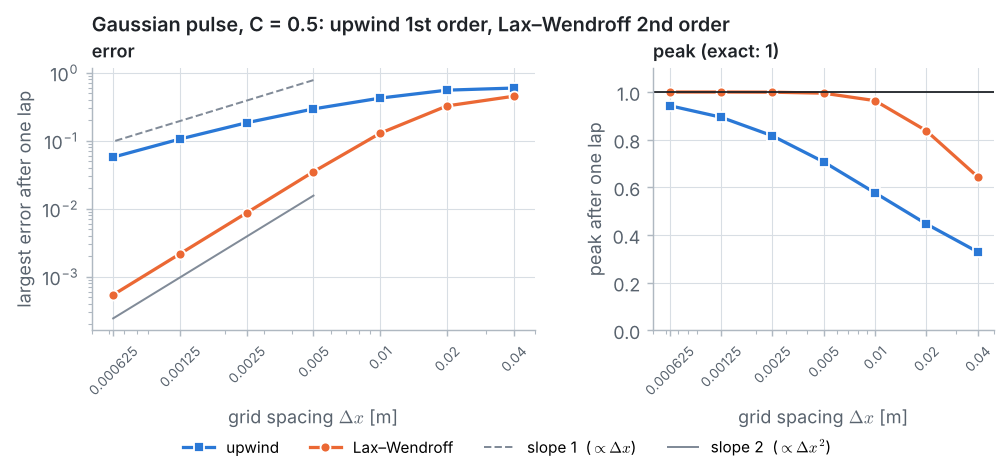

In [27]:
plots.convergence(dxs, errors, peaks)

* **Lax–Wendroff** is poor on the coarsest grids (with $N = 25$ the pulse is only 2.5 nodes wide), but from $N = 200$ on its error falls by a factor of 4 per halving of $\Delta x$: observed order **2.0**. On 400 intervals it keeps 99.9 % of the peak.
* **Upwind** converges, but slowly. Its error is almost entirely the loss of peak height by numerical diffusion, and it follows the modified-equation prediction on every grid. The observed order creeps up towards 1 (0.88 between $N = 800$ and $1600$): it reaches **1st order** only once $D_{num}\,t$ is small compared with $\sigma^2$. Even on 1600 intervals (3200 time steps) upwind keeps only 94 % of the peak, less than Lax–Wendroff on 100 intervals with 256 times less work.

### What this means for CFD codes

Every CFD code that computes an unsteady flow has an advection term and faces this choice. First-order upwind is robust and bounded but smears fronts, vortices and pulses; second-order central or Lax–Wendroff-type schemes are accurate but wiggle near sharp changes. Practical codes use high-resolution schemes (TVD schemes with flux limiters, which switch to upwind near jumps and to second order elsewhere) or a carefully controlled **stabilisation**. And the *time integrator* matters just as much: implicit methods such as the BDF schemes used by default in COMSOL are stable for any time step, but they damp waves too, just like upwinding (the COMSOL cross-check of this problem shows it).

---
## Summary

* The **advection equation** $u_t + c\,u_x = 0$ is **hyperbolic**: $u$ is carried unchanged along the characteristics $x - ct = \text{const}$, and the exact solution is the initial profile shifted by $c\,t$.
* The **Courant number** $C = c\,\Delta t/\Delta x$ is the distance the flow moves in one step, in grid intervals. The **CFL condition** $C \le 1$ is necessary for any explicit scheme with a three-point stencil.
* **Von Neumann analysis** follows each Fourier wave with its amplification factor $G$. **FTCS** has $|G| > 1$ for every wave and every $C$: it always blows up. **Upwind** and **Lax–Wendroff** are stable for $C \le 1$, **exact at $C = 1$**, and blow up for $C > 1$.
* **Upwind** is bounded but adds **numerical diffusion** $D_{num} = \tfrac{1}{2}c\,\Delta x\,(1 - C)$ (the false diffusion of Problem 5); the modified equation predicts its peak loss to 3 decimals. Only 1st order.
* **Lax–Wendroff** is 2nd order and keeps the peak, but its error is **dispersive**: short waves lag behind, giving wiggles behind sharp fronts.
* All three schemes **conserve** the total amount of dye.

## Try it yourself

1. Reverse the flow, `c = -1.0`. Which node is upwind now? Change `step_upwind` so it works for both signs of $c$. What happens if you forget?
2. Run upwind and Lax–Wendroff for **ten** laps at $C = 0.5$. How much of the Gaussian peak is left? Check the upwind value against the modified equation with $t = 10$ s.
3. At $C = 1.1$ run the Gaussian for 3 laps. When does the blow-up become visible? Use the largest $|G|$ to estimate how fast it grows.
4. Measure the order of accuracy with the **square pulse** instead of the Gaussian. Use the average error $\frac{1}{N}\sum|u_i - u_{exact}|$ instead of the largest. (Theory: about 1/2 for upwind and 2/3 for Lax–Wendroff: a jump spoils the order of every scheme.)
5. *Challenge:* implement the **Beam–Warming** scheme, $u_i^{n+1} = u_i - \tfrac{C}{2}(3u_i - 4u_{i-1} + u_{i-2}) + \tfrac{C^2}{2}(u_i - 2u_{i-1} + u_{i-2})$. Where are its wiggles: in front of or behind the square pulse? For which $C$ is it stable?